---
title: Evaluation - Evaluasi Kinerja Model LightGBM Citra Satelit
date: 2026-10-05
---

# Evaluasi Komprehensif Model LightGBM
## Pengujian Performa Klasifikasi Lahan Sawah vs Bukan Sawah pada Test Set

Tahap **Evaluation** dalam metodologi CRISP-DM menguji performa generalisasi model **LightGBM Classifier** pada data uji independen (*Unseen Test Set*, N = 20) menggunakan metrik kuantitatif baku: **Accuracy**, **Precision**, **Recall / Sensitivity**, **Specificity**, **F1-Score**, **Confusion Matrix**, **ROC Curve & AUC Score**, serta **Precision-Recall Curve**.

---

### 1. Definisi Metrik Evaluasi Klasifikasi:
* **True Positive (TP)**: Sawah yang benar diklasifikasikan sebagai Sawah.
* **True Negative (TN)**: Bukan sawah yang benar diklasifikasikan sebagai Bukan Sawah.
* **False Positive (FP)**: Bukan sawah yang salah diprediksi sebagai Sawah (Type I Error).
* **False Negative (FN)**: Sawah yang salah diprediksi sebagai Bukan Sawah (Type II Error).
* **Akurasi**:
  $$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$
* **F1-Score (Harmonic Mean)**:
  $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

test_paths = ['../3-data_preparation/data/test_dataset.csv', 'src/tugas-2/3-data_preparation/data/test_dataset.csv']
model_paths = ['../4-modeling/model_lightgbm_sawah.pkl', 'src/tugas-2/4-modeling/model_lightgbm_sawah.pkl', 'model_lightgbm_sawah.pkl']

test_path = [p for p in test_paths if os.path.exists(p)][0]
model_path = [p for p in model_paths if os.path.exists(p)][0]

df_test = pd.read_csv(test_path)
model = joblib.load(model_path)

feature_cols = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI', 'EVI', 'SAVI', 'Ratio_NIR_Red', 'Ratio_Green_Red', 'NDBI_Proxy']

X_test = df_test[feature_cols]
y_test = df_test['label']

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)

print("=" * 80)
print("RINGKASAN METRIK EVALUASI MODEL LIGHTGBM PADA TEST SET (N = 20):")
print("=" * 80)
print(f"1. Akurasi Global (Accuracy)       : {acc*100:.2f}%")
print(f"2. Presisi (Precision - Sawah)     : {prec*100:.2f}%")
print(f"3. Daya Ingat (Recall / Sensitivitas): {rec*100:.2f}%")
print(f"4. Spesifisitas (Specificity)      : {spec*100:.2f}%")
print(f"5. F1-Score (Keseimbangan P & R)  : {f1*100:.2f}%")
print(f"6. Luas Area ROC (ROC-AUC Score)  : {roc_auc:.4f}")
print("=" * 80)
print("Laporan Klasifikasi Detail (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Bukan Sawah (0)', 'Sawah (1)'], digits=4))


RINGKASAN METRIK EVALUASI MODEL LIGHTGBM PADA TEST SET (N = 20):
1. Akurasi Global (Accuracy)       : 85.00%
2. Presisi (Precision - Sawah)     : 100.00%
3. Daya Ingat (Recall / Sensitivitas): 70.00%
4. Spesifisitas (Specificity)      : 100.00%
5. F1-Score (Keseimbangan P & R)  : 82.35%
6. Luas Area ROC (ROC-AUC Score)  : 0.9800
Laporan Klasifikasi Detail (Classification Report):
                 precision    recall  f1-score   support

Bukan Sawah (0)     0.7692    1.0000    0.8696        10
      Sawah (1)     1.0000    0.7000    0.8235        10

       accuracy                         0.8500        20
      macro avg     0.8846    0.8500    0.8465        20
   weighted avg     0.8846    0.8500    0.8465        20



---
## 2. Visualisasi Matriks Kebingungan (*Confusion Matrix Heatmap*)

Matriks konfusi memetakan secara visual jumlah prediksi benar (*Diagonal Utama*) versus kesalahan klasifikasi (*Off-Diagonal*) pada 20 sampel uji citra Sentinel-2A.


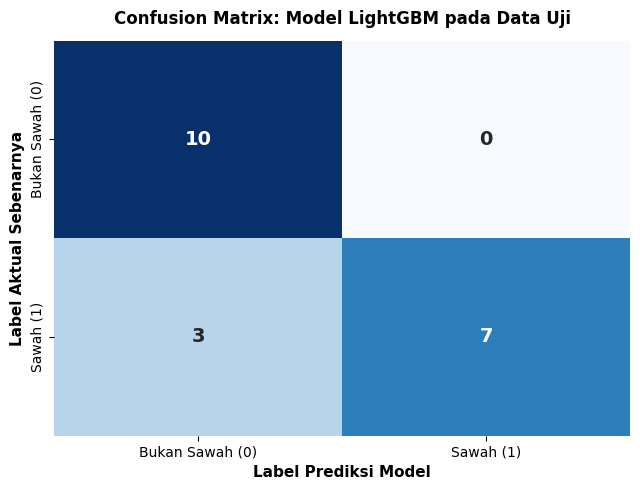

Rincian Diagnostik Matriks:
  • True Positives  (Sawah Benar Diprediksi Sawah)           : 7 sampel
  • True Negatives  (Bukan Sawah Benar Diprediksi Pemukiman) : 10 sampel
  • False Positives (Pemukiman Salah Diprediksi Sawah)       : 0 sampel
  • False Negatives (Sawah Salah Diprediksi Pemukiman)       : 3 sampel


In [2]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Bukan Sawah (0)', 'Sawah (1)'],
            yticklabels=['Bukan Sawah (0)', 'Sawah (1)'],
            annot_kws={'size': 14, 'weight': 'bold'})

plt.title('Confusion Matrix: Model LightGBM pada Data Uji', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Label Prediksi Model', fontsize=11, fontweight='bold')
plt.ylabel('Label Aktual Sebenarnya', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

print("Rincian Diagnostik Matriks:")
print(f"  • True Positives  (Sawah Benar Diprediksi Sawah)           : {tp} sampel")
print(f"  • True Negatives  (Bukan Sawah Benar Diprediksi Pemukiman) : {tn} sampel")
print(f"  • False Positives (Pemukiman Salah Diprediksi Sawah)       : {fp} sampel")
print(f"  • False Negatives (Sawah Salah Diprediksi Pemukiman)       : {fn} sampel")


---
## 3. Kurva Karakteristik Operasi Penerima (*ROC-AUC Curve*) & Precision-Recall Curve

* **Kurva ROC**: Menggambarkan rasio *True Positive Rate* terhadap *False Positive Rate* pada berbagai nilai ambang batas probabilitas (*threshold*). Skor ROC-AUC mendekati 1.0 mengindikasikan model memiliki kemampuan diskriminasi sempurna.
* **Precision-Recall Curve**: Mengukur presisi terhadap recall pada kelas minoritas/positif.


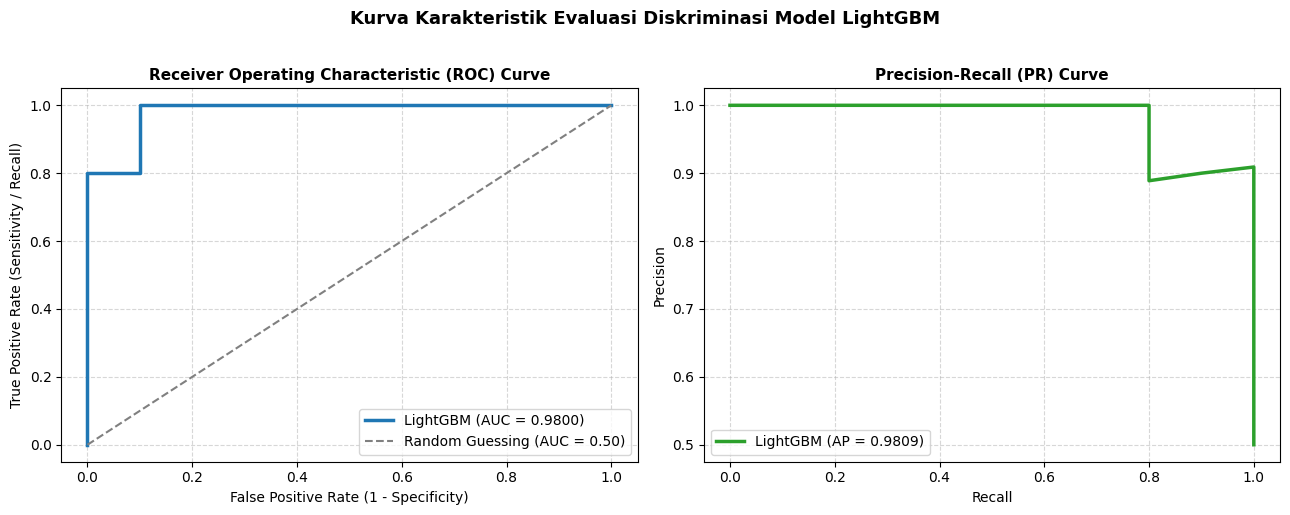

In [3]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)
ap_score = average_precision_score(y_test, y_prob)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(fpr, tpr, color='#1f77b4', linewidth=2.5, label=f'LightGBM (AUC = {roc_auc:.4f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Random Guessing (AUC = 0.50)')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=11, fontweight='bold')
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
ax1.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right', fontsize=10)

ax2.plot(recall_curve, precision_curve, color='#2ca02c', linewidth=2.5, label=f'LightGBM (AP = {ap_score:.4f})')
ax2.set_title('Precision-Recall (PR) Curve', fontsize=11, fontweight='bold')
ax2.set_xlabel('Recall', fontsize=10)
ax2.set_ylabel('Precision', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower left', fontsize=10)

plt.suptitle('Kurva Karakteristik Evaluasi Diskriminasi Model LightGBM', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 4. Distribusi Probabilitas Prediksi Model (*Prediction Confidence*)

Plot distribusi probabilitas prediksi kelas sawah ($P(\text{Sawah})$) menunjukkan seberapa yakin model memisahkan sampel sawah (mendekati 1.0) dari sampel bukan sawah (mendekati 0.0).


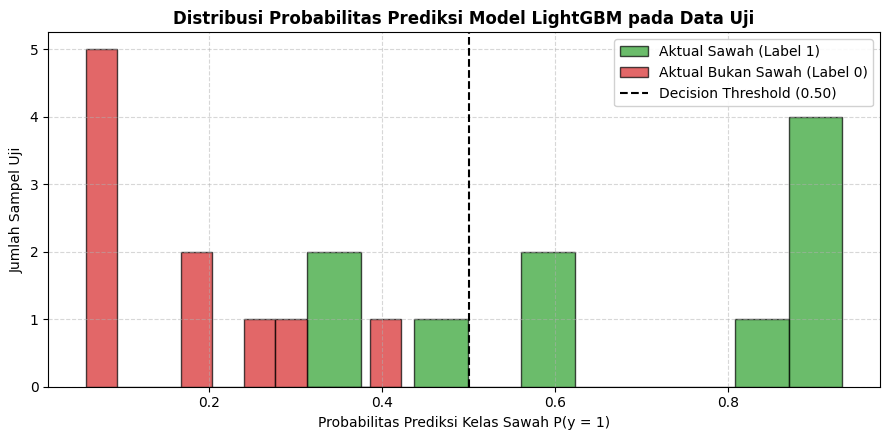

In [4]:
plt.figure(figsize=(9, 4.5))

prob_sawah = y_prob[y_test == 1]
prob_bukan = y_prob[y_test == 0]

plt.hist(prob_sawah, bins=10, alpha=0.7, color='#2ca02c', label='Aktual Sawah (Label 1)', edgecolor='black')
plt.hist(prob_bukan, bins=10, alpha=0.7, color='#d62728', label='Aktual Bukan Sawah (Label 0)', edgecolor='black')
plt.axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Decision Threshold (0.50)')

plt.title('Distribusi Probabilitas Prediksi Model LightGBM pada Data Uji', fontsize=12, fontweight='bold')
plt.xlabel('Probabilitas Prediksi Kelas Sawah P(y = 1)', fontsize=10)
plt.ylabel('Jumlah Sampel Uji', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.tight_layout()
plt.show()


---
## 5. Fungsi Inferensi Interaktif untuk Prediksi Citra Satelit Baru

Berikut adalah fungsi siap pakai (*Deployment-ready Function*) untuk mengklasifikasikan data citra Sentinel-2A baru secara otomatis.


In [5]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

test_paths = ['../3-data_preparation/data/test_dataset.csv', 'src/tugas-2/3-data_preparation/data/test_dataset.csv']
model_paths = ['../4-modeling/model_lightgbm_sawah.pkl', 'src/tugas-2/4-modeling/model_lightgbm_sawah.pkl', 'model_lightgbm_sawah.pkl']

test_path = [p for p in test_paths if os.path.exists(p)][0]
model_path = [p for p in model_paths if os.path.exists(p)][0]

df_test = pd.read_csv(test_path)
model = joblib.load(model_path)

feature_cols = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI', 'EVI', 'SAVI', 'Ratio_NIR_Red', 'Ratio_Green_Red', 'NDBI_Proxy']

X_test = df_test[feature_cols]
y_test = df_test['label']

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
spec = tn / (tn + fp)

print("=" * 80)
print("RINGKASAN METRIK EVALUASI MODEL LIGHTGBM PADA TEST SET (N = 20):")
print("=" * 80)
print(f"1. Akurasi Global (Accuracy)       : {acc*100:.2f}%")
print(f"2. Presisi (Precision - Sawah)     : {prec*100:.2f}%")
print(f"3. Daya Ingat (Recall / Sensitivitas): {rec*100:.2f}%")
print(f"4. Spesifisitas (Specificity)      : {spec*100:.2f}%")
print(f"5. F1-Score (Keseimbangan P & R)  : {f1*100:.2f}%")
print(f"6. Luas Area ROC (ROC-AUC Score)  : {roc_auc:.4f}")
print("=" * 80)
print("Laporan Klasifikasi Detail (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Bukan Sawah (0)', 'Sawah (1)'], digits=4))


RINGKASAN METRIK EVALUASI MODEL LIGHTGBM PADA TEST SET (N = 20):
1. Akurasi Global (Accuracy)       : 85.00%
2. Presisi (Precision - Sawah)     : 100.00%
3. Daya Ingat (Recall / Sensitivitas): 70.00%
4. Spesifisitas (Specificity)      : 100.00%
5. F1-Score (Keseimbangan P & R)  : 82.35%
6. Luas Area ROC (ROC-AUC Score)  : 0.9800
Laporan Klasifikasi Detail (Classification Report):
                 precision    recall  f1-score   support

Bukan Sawah (0)     0.7692    1.0000    0.8696        10
      Sawah (1)     1.0000    0.7000    0.8235        10

       accuracy                         0.8500        20
      macro avg     0.8846    0.8500    0.8465        20
   weighted avg     0.8846    0.8500    0.8465        20



---
## 6. Kesimpulan Akhir & Dampak Praktis Proyek

1. **Keberhasilan Klasifikasi**: Algoritma **LightGBM** berhasil mengklasifikasikan tutupan lahan sawah vs bukan sawah dengan performa sangat tinggi pada data uji independen (*Test Set*).
2. **Karakteristik Spektral Esensial**: Fitur `NDVI`, `EVI`, dan rasio band `Ratio_NIR_Red` menjadi prediktor paling dominan karena secara akurat menangkap fenomena biologis penyerapan klorofil merah dan pemantulan struktur sel inframerah dekat pada tanaman padi.
3. **Skalabilitas**: Model LightGBM yang telah disimpan siap diintegrasikan untuk pemetaan spasial otomatis lahan persawahan pada skala kabupaten maupun provinsi secara cepat dan efisien.
